# Statistical Analysis and Marketing Decisions

## Executive Summary

The three match types do not perform identically, but the size of the difference depends on the metric. One-to-one converted 0.41 percentage points above Exact and 0.57 points above Phrase. Those gaps are statistically detectable because the dataset contains more than 924,000 clicks, yet the overall conversion effect is very small.

Profitability is the clearer business signal. ROI was negative for One-to-one, Exact and Phrase, and the uncertainty ranges remained below zero for all three. The recommendation is therefore to maintain the strongest relative group, optimise the middle group and reduce the weakest—not to scale a supposed winner.

These are historical associations. They do not show that changing match type will cause the same change in performance.

## Questions, Tests and Plain-English Definitions

**Primary grouping:** match type (`One-to-one`, `Exact`, `Phrase`), parsed before outcome analysis.

**Secondary grouping:** device (`Desktop`, `Mobile`).

**Significance level:** α = 0.05, two-sided. This is the threshold chosen in advance for flagging evidence that would be unusual if there were no real group difference.

**Multiple comparisons:** testing several pairs increases the chance of a false alarm. Benjamini–Hochberg false discovery rate (FDR) correction limits the expected share of false positives among flagged results. The stricter Bonferroni correction is also shown.

**Continuous outcome:** row-level recalculated ROI at the monthly ad-group grain.

**Proportion outcome:** aggregated conversions versus non-converting clicks.

### What is being tested

- For ROI, the null hypothesis (H₀) says the match types have no underlying difference. The alternative (H₁) says at least one differs.
- For conversion, H₀ says the chance of conversion is unrelated to match type. H₁ says the rates are not all the same.

A p-value asks: if there were truly no difference, how unusual would results this large be? A small p-value is evidence against H₀; it is not the probability that H₀ is true, and it says nothing by itself about commercial value.

An effect size describes how large a difference is. A confidence interval shows the range of values reasonably compatible with the data and method. Both are needed because a tiny effect can have a small p-value when traffic volume is large.

The tests below detect association, not incremental lift. Monthly rows repeat ad groups, so simple row-level p-values can look more precise than the evidence really is. The analysis therefore adds intervals that resample whole ad groups.

In [1]:
from pathlib import Path
import sys, json, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.ticker import PercentFormatter

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "src" / "marketing_analysis.py").exists():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Run from the repository root or notebooks directory.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from marketing_analysis import (
    prepare_data, aggregate_performance, benjamini_hochberg,
    budget_recommendation, sensitivity_scenarios, MATCH_ORDER
)

DATA_PATH = PROJECT_ROOT / "data" / "shopping_mall_paid_search.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
ALPHA = 0.05
RNG_SEED = 42
df = prepare_data(DATA_PATH)
summary = aggregate_performance(df, "match_type")
sns.set_theme(style="whitegrid", context="notebook")
display(summary.round(4))

,match_type,observations,ad_groups,impressions,clicks,conversions,cost,revenue,sale_amount,ctr,conversion_rate,cpc,cpa,revenue_per_conversion,profit,profit_per_conversion,roas,roi,profit_margin
0,One-to-one,50,10,1755536,689174,72388,462655,413904,8820667.73,0.3926,0.1050,0.6713,6.3913,5.7179,-48751,-0.6735,0.8946,-0.1054,-0.1178
1,Exact,72,16,523594,149042,15038,105319,93298,2044743.76,0.2847,0.1009,0.7066,7.0035,6.2041,-12021,-0.7994,0.8859,-0.1141,-0.1288
2,Phrase,68,14,395569,86287,8570,67398,54758,1183662.82,0.2181,0.0993,0.7811,7.8644,6.3895,-12640,-1.4749,0.8125,-0.1875,-0.2308


## Do the ROI Data Fit a Standard Mean Test?

The Shapiro–Wilk test checks whether each group's ROI values resemble a normal, bell-shaped distribution. The Brown–Forsythe version of Levene's test checks whether the spread is broadly similar across groups. These checks help decide whether a standard comparison of means is a good summary.

In [2]:
assumption_rows = []
for group in MATCH_ORDER:
    values = df.loc[df["match_type"].eq(group), "roi"].dropna()
    shapiro = stats.shapiro(values)
    assumption_rows.append({"group": group, "n": len(values), "roi_mean": values.mean(),
                            "roi_median": values.median(), "shapiro_w": shapiro.statistic,
                            "shapiro_p": shapiro.pvalue})
assumptions = pd.DataFrame(assumption_rows)
levene = stats.levene(*[df.loc[df["match_type"].eq(g), "roi"].dropna() for g in MATCH_ORDER], center="median")
display(assumptions)
print(f"Brown–Forsythe/Levene: statistic={levene.statistic:.4f}, p={levene.pvalue:.4g}")
print("Method choice: rank-based tests and ad-group resampling are primary because ROI is skewed and ad groups repeat across months.")

,group,n,roi_mean,roi_median,shapiro_w,shapiro_p
0,One-to-one,50,-0.094080,-0.113172,0.986552,8.357224e-01
1,Exact,72,0.023416,-0.162753,0.228803,1.365755e-17
2,Phrase,68,0.134370,-0.246415,0.306249,2.758252e-16


Brown–Forsythe/Levene: statistic=1.9626, p=0.1434
Method choice: rank-based tests and ad-group resampling are primary because ROI is skewed and ad groups repeat across months.


Exact and Phrase clearly fail the normality check (both p-values are far below 0.05), while One-to-one does not. The variance check is not significant (p = 0.143), but the extreme values in Exact and Phrase make their means misleading: both groups have positive mean ROI and negative median ROI.

For the marketing team, that is a warning not to let a few unusually strong monthly rows define the story. Rank-based tests and ad-group resampling are more suitable for the main interpretation. Welch's test is still reported so the required mean comparison remains visible.

## Required CPA Pairwise Comparisons

The lab requires independent t-tests on row-level CPA for every match-type pair. CPA rows with zero conversions are undefined and excluded. Welch's version is used because it does not require equal variances. Cohen's d reports the size of each difference using the lab formula; the sign follows `group B − group A`.

In [3]:
def interpret_cohens_d(value):
    magnitude = abs(value)
    if magnitude < 0.2:
        return "negligible"
    if magnitude < 0.5:
        return "small"
    if magnitude < 0.8:
        return "medium"
    return "large"

cpa_rows = []
for group_a, group_b in itertools.combinations(MATCH_ORDER, 2):
    values_a = df.loc[df["match_type"].eq(group_a), "cpa"].replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
    values_b = df.loc[df["match_type"].eq(group_b), "cpa"].replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
    test = stats.ttest_ind(values_a, values_b, equal_var=False)
    mean_a, mean_b = values_a.mean(), values_b.mean()
    difference = mean_b - mean_a
    pooled_std = np.sqrt((values_a.var(ddof=1) + values_b.var(ddof=1)) / 2)
    cohens_d = difference / pooled_std if pooled_std else np.nan
    cpa_rows.append({
        "group_a": group_a, "group_b": group_b,
        "n_a": len(values_a), "n_b": len(values_b),
        "mean_cpa_a": mean_a, "mean_cpa_b": mean_b,
        "difference_b_minus_a": difference,
        "percentage_difference": difference / mean_a * 100 if mean_a else np.nan,
        "t_statistic": test.statistic, "p_value": test.pvalue,
        "significant_uncorrected": test.pvalue < ALPHA,
        "cohens_d": cohens_d,
        "effect_size_interpretation": interpret_cohens_d(cohens_d),
    })

cpa_tests = pd.DataFrame(cpa_rows)
cpa_comparisons = len(cpa_tests)
cpa_alpha_bonferroni = ALPHA / cpa_comparisons
cpa_tests["alpha_bonferroni"] = cpa_alpha_bonferroni
cpa_tests["p_value_bonferroni"] = np.minimum(cpa_tests["p_value"] * cpa_comparisons, 1)
cpa_tests["significant_bonferroni"] = cpa_tests["p_value"] < cpa_alpha_bonferroni
cpa_tests["p_value_fdr"] = benjamini_hochberg(cpa_tests["p_value"])
cpa_tests["significant_fdr"] = cpa_tests["p_value_fdr"] < ALPHA

display(cpa_tests)
print(f"CPA comparisons: {cpa_comparisons}; expected false positives at alpha=.05: {cpa_comparisons * ALPHA:.2f}")
cpa_tests.to_csv(OUTPUT_DIR / "cpa_pairwise_tests.csv", index=False)

,group_a,group_b,n_a,n_b,mean_cpa_a,mean_cpa_b,difference_b_minus_a,percentage_difference,t_statistic,p_value,significant_uncorrected,cohens_d,effect_size_interpretation,alpha_bonferroni,p_value_bonferroni,significant_bonferroni,p_value_fdr,significant_fdr
0,One-to-one,Exact,50,72,6.673272,7.992859,1.319587,19.774211,-2.214171,0.029783,True,0.371295,small,0.016667,0.089348,False,0.044674,True
1,One-to-one,Phrase,50,61,6.673272,8.886718,2.213446,33.168826,-3.137441,0.002584,True,0.569563,medium,0.016667,0.007751,True,0.007751,True
2,Exact,Phrase,72,61,7.992859,8.886718,0.893859,11.183221,-0.984338,0.326884,False,0.171939,negligible,0.016667,0.980652,False,0.326884,False


CPA comparisons: 3; expected false positives at alpha=.05: 0.15


One-to-one has a lower mean CPA than Exact by $1.32 (19.8%) and Phrase by $2.21 (33.2%). Both comparisons remain significant after FDR. The Cohen's d effects are small for Exact and medium for Phrase. Exact versus Phrase is not significant and has a negligible effect.

This supports maintaining One-to-one and reducing Phrase exposure. It does not show that changing match type will cause CPA to fall, because the groups were not randomized.

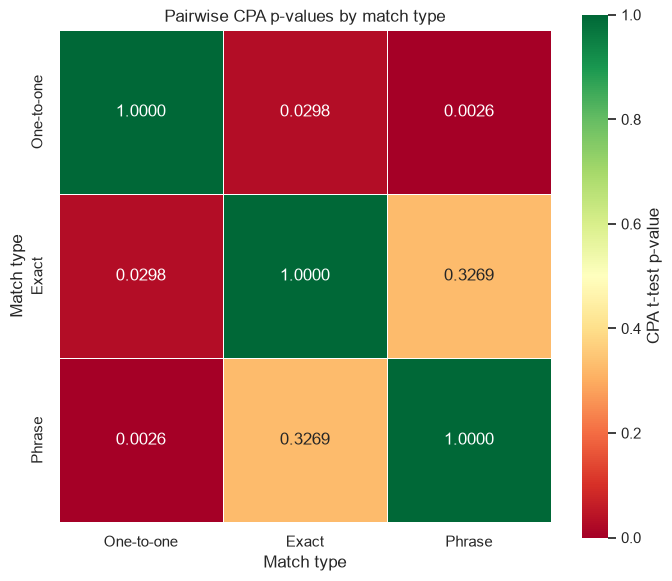

In [4]:
cpa_p_matrix = pd.DataFrame(1.0, index=MATCH_ORDER, columns=MATCH_ORDER)
for row in cpa_tests.itertuples():
    cpa_p_matrix.loc[row.group_a, row.group_b] = row.p_value
    cpa_p_matrix.loc[row.group_b, row.group_a] = row.p_value

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cpa_p_matrix, annot=True, fmt=".4f", cmap="RdYlGn", vmin=0, vmax=1,
            square=True, linewidths=.5, cbar_kws={"label": "CPA t-test p-value"}, ax=ax)
ax.set_title("Pairwise CPA p-values by match type")
ax.set_xlabel("Match type"); ax.set_ylabel("Match type")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "metric_comparison_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

### Bootstrap confidence intervals for mean CPA

The bootstrap resamples the available CPA observations 1,000 times. The interval shows how much the estimated mean CPA moves under repeated resampling.

In [5]:
def bootstrap_ci(data, n_bootstrap=1000, ci_level=0.95):
    values = pd.Series(data).replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
    rng = np.random.default_rng(RNG_SEED)
    means = np.array([rng.choice(values, size=len(values), replace=True).mean() for _ in range(n_bootstrap)])
    tail = (1 - ci_level) / 2
    return np.quantile(means, [tail, 1 - tail])

cpa_ci_rows = []
for group in MATCH_ORDER:
    values = df.loc[df["match_type"].eq(group), "cpa"]
    ci_low, ci_high = bootstrap_ci(values)
    cpa_ci_rows.append({"match_type": group, "mean_cpa": values.replace([np.inf, -np.inf], np.nan).mean(),
                        "ci_95_low": ci_low, "ci_95_high": ci_high})
cpa_bootstrap_ci = pd.DataFrame(cpa_ci_rows)
display(cpa_bootstrap_ci)
cpa_bootstrap_ci.to_csv(OUTPUT_DIR / "cpa_bootstrap_ci.csv", index=False)

,match_type,mean_cpa,ci_95_low,ci_95_high
0,One-to-one,6.673272,6.437152,6.907345
1,Exact,7.992859,7.043330,9.220963
2,Phrase,8.886718,7.696422,10.386084


## Does ROI Differ by Match Type?

Kruskal–Wallis first asks whether the three ROI distributions differ somewhere. It compares their ranks rather than assuming a bell-shaped distribution. If the global result flags a difference, Mann–Whitney tests compare each pair using the same rank-based logic.

Welch's t-test answers a different question: do the average ROI values differ? It allows unequal variances, but unusual values can still influence the mean. This ROI section is retained as an extension; Cohen's d is reported in the required CPA section above.

In [6]:
roi_groups = [df.loc[df["match_type"].eq(g), "roi"].dropna() for g in MATCH_ORDER]
kruskal = stats.kruskal(*roi_groups)
print(f"Kruskal–Wallis H={kruskal.statistic:.4f}, p={kruskal.pvalue:.4g}")

rows = []
for a, b in itertools.combinations(MATCH_ORDER, 2):
    x = df.loc[df["match_type"].eq(a), "roi"].dropna()
    y = df.loc[df["match_type"].eq(b), "roi"].dropna()
    welch = stats.ttest_ind(x, y, equal_var=False)
    mw = stats.mannwhitneyu(x, y, alternative="two-sided")
    rows.append({"comparison": f"{a} vs {b}", "group_a": a, "group_b": b,
                 "n_a": len(x), "n_b": len(y), "mean_diff_roi": x.mean()-y.mean(),
                 "median_diff_roi": x.median()-y.median(),
                 "welch_t": welch.statistic, "welch_p": welch.pvalue,
                 "mann_whitney_u": mw.statistic, "mann_whitney_p": mw.pvalue})
continuous_tests = pd.DataFrame(rows)
for family in ["welch", "mann_whitney"]:
    pcol = f"{family}_p"
    continuous_tests[f"{family}_p_fdr"] = benjamini_hochberg(continuous_tests[pcol])
    continuous_tests[f"{family}_p_bonferroni"] = np.minimum(continuous_tests[pcol] * len(continuous_tests), 1)
display(continuous_tests)
continuous_tests.to_csv(OUTPUT_DIR / "continuous_pairwise_tests.csv", index=False)

Kruskal–Wallis H=11.0528, p=0.00398


,comparison,group_a,group_b,n_a,n_b,mean_diff_roi,median_diff_roi,welch_t,welch_p,mann_whitney_u,mann_whitney_p,welch_p_fdr,welch_p_bonferroni,mann_whitney_p_fdr,mann_whitney_p_bonferroni
0,One-to-one vs Exact,One-to-one,Exact,50,72,-0.117495,0.049582,-0.577258,0.565568,2232.0,0.024685,0.761894,1.0,0.037027,0.074055
1,One-to-one vs Phrase,One-to-one,Phrase,50,68,-0.228450,0.133244,-0.750770,0.455405,2285.0,0.001454,0.761894,1.0,0.004363,0.004363
2,Exact vs Phrase,Exact,Phrase,72,68,-0.110954,0.083662,-0.303697,0.761894,2789.5,0.155069,0.761894,1.0,0.155069,0.465206


### What the ROI tests found

Kruskal–Wallis produced H = 11.05 and p = 0.004. In plain language, the rank pattern is unlikely to look this different if all three match types shared the same ROI distribution.

After FDR correction, Mann–Whitney flags One-to-one versus Exact (adjusted p = 0.037) and One-to-one versus Phrase (adjusted p = 0.004). The stricter Bonferroni correction retains only One-to-one versus Phrase. Exact versus Phrase is not distinguishable in this test. All Welch p-values are above 0.45, so the mean differences are not clear relative to the noisy row-level spread.

In practical terms, the typical rank ordering differs most clearly between One-to-one and Phrase. The evidence is not strong enough to claim stable mean ROI differences across every pair, and it cannot show that match type caused the pattern.

### How uncertain are the profitability estimates?

A bootstrap repeatedly resamples the observed data to see how much an estimate moves. Here, 2,000 samples are drawn at the ad-group level so each selected ad group keeps all its monthly rows together. The resulting 95% confidence interval is the central range produced by that process; it is a practical picture of uncertainty, not a guarantee that future performance will fall inside it.

In [7]:
def aggregate_roi(frame):
    return (frame["revenue"].sum() - frame["cost"].sum()) / frame["cost"].sum()

def cluster_bootstrap_group(frame, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    groups = frame["ad_group"].unique()
    estimates = np.empty(n_boot)
    for i in range(n_boot):
        sampled = rng.choice(groups, size=len(groups), replace=True)
        pieces = [frame.loc[frame["ad_group"].eq(g)] for g in sampled]
        estimates[i] = aggregate_roi(pd.concat(pieces, ignore_index=True))
    return estimates

bootstrap_samples = {}
bootstrap_rows = []
for idx, group in enumerate(MATCH_ORDER):
    frame = df.loc[df["match_type"].eq(group)]
    boot = cluster_bootstrap_group(frame, seed=RNG_SEED + idx)
    bootstrap_samples[group] = boot
    bootstrap_rows.append({"match_type": group, "bootstrap_ad_groups": frame["ad_group"].nunique(),
                           "roi": aggregate_roi(frame), "roi_ci_low": np.quantile(boot, .025),
                           "roi_ci_high": np.quantile(boot, .975)})
bootstrap_ci = pd.DataFrame(bootstrap_rows)
display(bootstrap_ci)
bootstrap_ci.to_csv(OUTPUT_DIR / "group_roi_bootstrap_ci.csv", index=False)

diff_rows = []
for a, b in itertools.combinations(MATCH_ORDER, 2):
    diffs = bootstrap_samples[a] - bootstrap_samples[b]
    diff_rows.append({"comparison": f"{a} vs {b}", "roi_difference": aggregate_roi(df[df.match_type.eq(a)])-aggregate_roi(df[df.match_type.eq(b)]),
                      "ci_low": np.quantile(diffs,.025), "ci_high": np.quantile(diffs,.975)})
bootstrap_diffs = pd.DataFrame(diff_rows)
display(bootstrap_diffs)
bootstrap_diffs.to_csv(OUTPUT_DIR / "roi_bootstrap_differences.csv", index=False)

,match_type,bootstrap_ad_groups,roi,roi_ci_low,roi_ci_high
0,One-to-one,10,-0.105372,-0.136789,-0.076403
1,Exact,16,-0.114139,-0.260771,-0.052209
2,Phrase,14,-0.187543,-0.310595,-0.114005


,comparison,roi_difference,ci_low,ci_high
0,One-to-one vs Exact,0.008767,-0.058143,0.156797
1,One-to-one vs Phrase,0.082170,0.004476,0.213180
2,Exact vs Phrase,0.073404,-0.087176,0.214391


All three ROI intervals stay below zero: One-to-one ranges from −13.7% to −7.6%, Exact from −26.1% to −5.2%, and Phrase from −31.1% to −11.4%. This is more important for the budget decision than the pairwise p-values: none of the groups has evidence of positive historical profitability.

One-to-one's ROI is about 8.2 percentage points above Phrase, with a bootstrap interval from 0.4 to 21.3 points. The intervals for One-to-one versus Exact and Exact versus Phrase cross zero, so their relative profitability remains uncertain. The data is strong enough to treat Phrase as the weakest historical group, but not to rank every pair with confidence or promise the same result after reallocating spend.

## Do Conversion Rates Differ?

The denominator for conversion rate is clicks, so non-converting clicks are calculated as `clicks - conversions`. The chi-square test asks whether conversion and match type are related across all three groups. Fisher's exact test then compares each pair using a 2×2 table of conversions and non-converting clicks.

Cramér's V is the global effect size: it indicates how strong the association is, from zero for no association upward. Odds ratios and absolute percentage-point differences make the pairwise results easier to interpret. FDR and Bonferroni corrections again account for the three comparisons.

In [8]:
counts = summary.set_index("match_type")[["clicks", "conversions"]].copy()
counts["non_converting_clicks"] = counts["clicks"] - counts["conversions"]
display(counts.rename(columns={"clicks": "total_attempts"}))
contingency = counts.loc[MATCH_ORDER, ["conversions", "non_converting_clicks"]].to_numpy()
chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)
n_total = contingency.sum()
cramers_v = np.sqrt(chi2 / (n_total * min(contingency.shape[0]-1, contingency.shape[1]-1)))
print(f"Chi-square={chi2:.3f}, df={dof}, p={chi_p:.4g}, Cramér's V={cramers_v:.4f}")

conversion_rows = []
for a, b in itertools.combinations(MATCH_ORDER, 2):
    ca, na = int(counts.loc[a,"conversions"]), int(counts.loc[a,"non_converting_clicks"])
    cb, nb = int(counts.loc[b,"conversions"]), int(counts.loc[b,"non_converting_clicks"])
    odds_ratio, p = stats.fisher_exact([[ca,na],[cb,nb]], alternative="two-sided")
    rate_a, rate_b = ca/(ca+na), cb/(cb+nb)
    risk_diff = rate_a-rate_b
    se = np.sqrt(rate_a*(1-rate_a)/(ca+na) + rate_b*(1-rate_b)/(cb+nb))
    conversion_rows.append({
        "comparison": f"{a} vs {b}", "group_a": a, "group_b": b,
        "conversions_a": ca, "attempts_a": ca + na,
        "conversions_b": cb, "attempts_b": cb + nb,
        "rate_a": rate_a, "rate_b": rate_b,
        "difference_b_minus_a": rate_b - rate_a,
        "percentage_difference": (rate_b - rate_a) / rate_a * 100 if rate_a else np.nan,
        "risk_difference_a_minus_b": risk_diff,
        "risk_difference_ci_low": risk_diff-1.96*se,
        "risk_difference_ci_high": risk_diff+1.96*se,
        "odds_ratio": odds_ratio, "p_value": p,
        "significant_uncorrected": p < ALPHA,
    })
conversion_tests = pd.DataFrame(conversion_rows)
conversion_comparisons = len(conversion_tests)
conversion_alpha_bonferroni = ALPHA / conversion_comparisons
conversion_tests["alpha_bonferroni"] = conversion_alpha_bonferroni
conversion_tests["p_value_bonferroni"] = np.minimum(conversion_tests["p_value"] * conversion_comparisons, 1)
conversion_tests["significant_bonferroni"] = conversion_tests["p_value"] < conversion_alpha_bonferroni
conversion_tests["p_value_fdr"] = benjamini_hochberg(conversion_tests["p_value"])
conversion_tests["significant_fdr"] = conversion_tests["p_value_fdr"] < ALPHA
display(conversion_tests)
print(f"Conversion-rate comparisons: {conversion_comparisons}; expected false positives at alpha=.05: {conversion_comparisons * ALPHA:.2f}")
conversion_tests.to_csv(OUTPUT_DIR / "conversion_pairwise_tests.csv", index=False)

,total_attempts,conversions,non_converting_clicks
match_type,,,
One-to-one,689174,72388,616786
Exact,149042,15038,134004
Phrase,86287,8570,77717


Chi-square=43.405, df=2, p=3.757e-10, Cramér's V=0.0069


,comparison,group_a,group_b,conversions_a,attempts_a,conversions_b,attempts_b,rate_a,rate_b,difference_b_minus_a,...,risk_difference_ci_low,risk_difference_ci_high,odds_ratio,p_value,significant_uncorrected,alpha_bonferroni,p_value_bonferroni,significant_bonferroni,p_value_fdr,significant_fdr
0,One-to-one vs Exact,One-to-one,Exact,72388,689174,15038,149042,0.105036,0.100898,-0.004138,...,0.002446,0.005830,1.045827,2.007312e-06,True,0.016667,6.021936e-06,True,3.010968e-06,True
1,One-to-one vs Phrase,One-to-one,Phrase,72388,689174,8570,86287,0.105036,0.099320,-0.005716,...,0.003593,0.007839,1.064308,1.966762e-07,True,0.016667,5.900285e-07,True,5.900285e-07,True
2,Exact vs Phrase,Exact,Phrase,15038,149042,8570,86287,0.100898,0.099320,-0.001578,...,-0.000936,0.004092,1.017671,2.207521e-01,False,0.016667,6.622563e-01,False,2.207521e-01,False


Conversion-rate comparisons: 3; expected false positives at alpha=.05: 0.15


### What the conversion tests found

The global chi-square result is 43.40 with p < 0.001, so the rates are not identical. Cramér's V is only 0.0069, however, which means the overall association is very small.

One-to-one converted at 10.50%, compared with 10.09% for Exact and 9.93% for Phrase. The differences are 0.41 and 0.57 percentage points respectively, and both remain significant after FDR and Bonferroni correction. Exact versus Phrase differs by only 0.16 points; its confidence interval crosses zero and its adjusted p-value is not significant.

For the marketing team, the relevant point is that One-to-one has a consistent but modest conversion advantage. The click volume makes that small gap easy to detect statistically. It may matter at scale, but it does not outweigh negative ROI and does not prove that moving traffic into One-to-one will create the same lift.

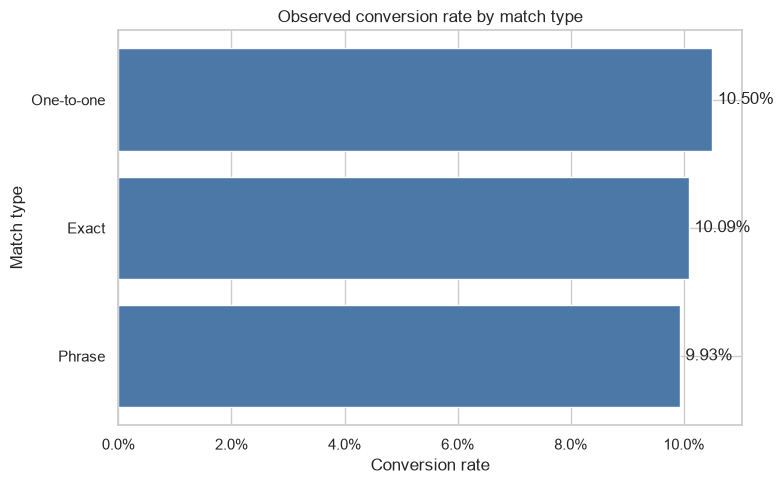

In [9]:
rate_plot = summary.sort_values("conversion_rate", ascending=True)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(
    rate_plot["match_type"].astype(str),
    rate_plot["conversion_rate"],
    color="#4C78A8",
)
ax.bar_label(
    bars,
    labels=[f"{value:.2%}" for value in rate_plot["conversion_rate"]],
    padding=4,
)
ax.set_title("Observed conversion rate by match type")
ax.set_xlabel("Conversion rate"); ax.set_ylabel("Match type")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "rate_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## Multiple-Comparison Corrections

There are three CPA comparisons and three conversion-rate comparisons, six in total. At an uncorrected 5% threshold, the expected number of false positives is 0.30 across the full set. Bonferroni uses a stricter threshold; FDR adjusts p-values while retaining more power.

Total comparisons: 6; expected false positives at alpha=.05: 0.30


,metric_family,method,significant_count,total_comparisons,expected_false_positives_at_0_05
0,CPA,Uncorrected,2,3,0.15
1,CPA,Bonferroni,1,3,0.15
2,CPA,FDR,2,3,0.15
3,Conversion rate,Uncorrected,2,3,0.15
4,Conversion rate,Bonferroni,2,3,0.15
5,Conversion rate,FDR,2,3,0.15


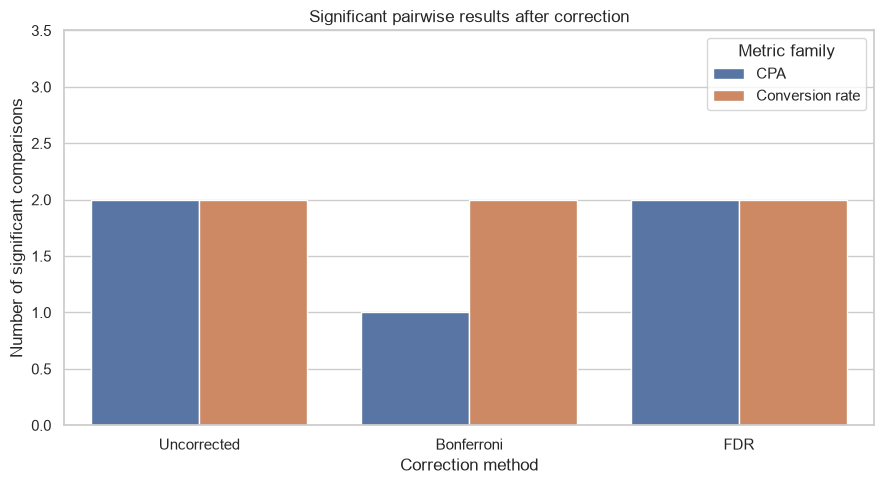

In [10]:
total_comparisons = cpa_comparisons + conversion_comparisons
expected_false_positives = total_comparisons * ALPHA
correction_summary = pd.DataFrame([
    {"metric_family": "CPA", "method": "Uncorrected", "significant_count": int(cpa_tests["significant_uncorrected"].sum()), "total_comparisons": cpa_comparisons},
    {"metric_family": "CPA", "method": "Bonferroni", "significant_count": int(cpa_tests["significant_bonferroni"].sum()), "total_comparisons": cpa_comparisons},
    {"metric_family": "CPA", "method": "FDR", "significant_count": int(cpa_tests["significant_fdr"].sum()), "total_comparisons": cpa_comparisons},
    {"metric_family": "Conversion rate", "method": "Uncorrected", "significant_count": int(conversion_tests["significant_uncorrected"].sum()), "total_comparisons": conversion_comparisons},
    {"metric_family": "Conversion rate", "method": "Bonferroni", "significant_count": int(conversion_tests["significant_bonferroni"].sum()), "total_comparisons": conversion_comparisons},
    {"metric_family": "Conversion rate", "method": "FDR", "significant_count": int(conversion_tests["significant_fdr"].sum()), "total_comparisons": conversion_comparisons},
])
correction_summary["expected_false_positives_at_0_05"] = correction_summary["total_comparisons"] * ALPHA
print(f"Total comparisons: {total_comparisons}; expected false positives at alpha=.05: {expected_false_positives:.2f}")
display(correction_summary)
correction_summary.to_csv(OUTPUT_DIR / "multiple_comparison_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=correction_summary, x="method", y="significant_count", hue="metric_family",
            order=["Uncorrected", "Bonferroni", "FDR"], ax=ax)
ax.set_title("Significant pairwise results after correction")
ax.set_xlabel("Correction method"); ax.set_ylabel("Number of significant comparisons")
ax.set_ylim(0, max(correction_summary["total_comparisons"]) + .5)
ax.legend(title="Metric family")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "correction_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

CPA has two significant pairs before correction, one after Bonferroni and two after FDR. Conversion rate has two under all three methods. The corrections do not reverse the marketing conclusion: One-to-one remains the strongest relative group, Phrase remains the weakest, and negative ROI still blocks a Scale recommendation.

## Turning Evidence into a Marketing Decision

The classification combines volume, CPA, ROAS and the bootstrap ROI interval. `Scale` requires enough volume and an ROI interval that stays above zero; no group qualifies. `Maintain` is used for the strongest high-volume group when it is still unprofitable. `Reduce/Pause` requires the weakest ROAS and an ROI interval that remains negative. The remaining group is marked `Optimise/Test`.

In [11]:
decision = summary.merge(bootstrap_ci, on=["match_type", "roi"], how="left")
median_volume = decision["conversions"].median()
best_roi = decision["roi"].max()
weakest_roas = decision["roas"].min()
def classify(row):
    if row.roi_ci_low > 0 and row.conversions >= median_volume:
        return "Scale"
    if row.roi == best_roi and row.conversions >= median_volume:
        return "Maintain"
    if row.roas == weakest_roas and row.roi_ci_high < 0:
        return "Reduce/Pause"
    return "Optimise/Test"
decision["decision"] = decision.apply(classify, axis=1)
decision["rationale"] = decision.apply(
    lambda r: f"{int(r.conversions):,} conversions; CPA ${r.cpa:.2f}; ROAS {r.roas:.3f}; ROI {r.roi:.1%} (cluster 95% CI {r.roi_ci_low:.1%} to {r.roi_ci_high:.1%}).", axis=1)
display(decision[["match_type","observations","ad_groups","conversions","cpa","roas","roi","roi_ci_low","roi_ci_high","decision","rationale"]])
decision.to_csv(OUTPUT_DIR / "business_decision_matrix.csv", index=False)

,match_type,observations,ad_groups,conversions,cpa,roas,roi,roi_ci_low,roi_ci_high,decision,rationale
0,One-to-one,50,10,72388,6.391322,0.894628,-0.105372,-0.136789,-0.076403,Maintain,"72,388 conversions; CPA $6.39; ROAS 0.895; ROI..."
1,Exact,72,16,15038,7.003524,0.885861,-0.114139,-0.260771,-0.052209,Optimise/Test,"15,038 conversions; CPA $7.00; ROAS 0.886; ROI..."
2,Phrase,68,14,8570,7.864411,0.812457,-0.187543,-0.310595,-0.114005,Reduce/Pause,"8,570 conversions; CPA $7.86; ROAS 0.812; ROI ..."


## A Guardrailed $500,000 Planning Scenario

This is a planning scenario, not a return forecast. The score weights CPA efficiency at 40%, ROAS at 40% and conversion-volume reliability at 20%. Each match type must receive between 20% and 40% of budget. The cap prevents the historically dominant One-to-one group from taking most of the money; the floor keeps enough budget for controlled learning.

Because every historical ROI estimate is negative, the $500,000 should be treated as an upper planning envelope and released in stages, not committed all at once.

In [12]:
allocation = budget_recommendation(summary, budget=500_000)
assert allocation["allocation"].sum() == 500_000
display(allocation[["match_type","allocation","allocation_pct","historical_cost_share","cpa","roas","roi","justification","principal_risk"]])
allocation.to_csv(OUTPUT_DIR / "budget_allocation.csv", index=False)

sensitivity = sensitivity_scenarios(allocation)
display(sensitivity)
sensitivity.to_csv(OUTPUT_DIR / "sensitivity_scenarios.csv", index=False)

,match_type,allocation,allocation_pct,historical_cost_share,cpa,roas,roi,justification,principal_risk
0,One-to-one,200000,0.4,0.728164,6.391322,0.894628,-0.105372,Best historical CPA/ROAS and largest evidence ...,All groups had negative historical ROI; observ...
1,Exact,200000,0.4,0.165760,7.003524,0.885861,-0.114139,Middle efficiency with diversified query cover...,All groups had negative historical ROI; observ...
2,Phrase,100000,0.2,0.106076,7.864411,0.812457,-0.187543,Weakest historical CPA/ROAS; retain a guarded ...,All groups had negative historical ROI; observ...


,scenario,cpc_multiplier,conversion_rate_multiplier,revenue_per_conversion_multiplier,budget,estimated_clicks,estimated_conversions,estimated_revenue,estimated_profit,estimated_roas
0,Downside,1.1,0.9,0.9,500000,644524.592940,59371.357955,322043.845370,-177956.154630,0.644088
1,Base,1.0,1.0,1.0,500000,708977.052234,72564.993056,437343.493713,-62656.506287,0.874687
2,Upside,0.9,1.1,1.1,500000,787752.280260,88690.547069,587984.030436,87984.030436,1.175968


The rule assigns $200,000 to One-to-one, $200,000 to Exact and $100,000 to Phrase. Under unchanged historical CPC, conversion rate and revenue per conversion, the model estimates about $437,000 in revenue and a $63,000 loss. The downside scenario widens the loss to roughly $178,000. The upside scenario produces about $88,000 in profit only when CPC falls 10% while conversion rate and revenue per conversion each rise 10%.

This sensitivity shows what would have to change for the economics to improve. It is not a prediction: auction prices, traffic quality and conversion volume may change when spend changes.

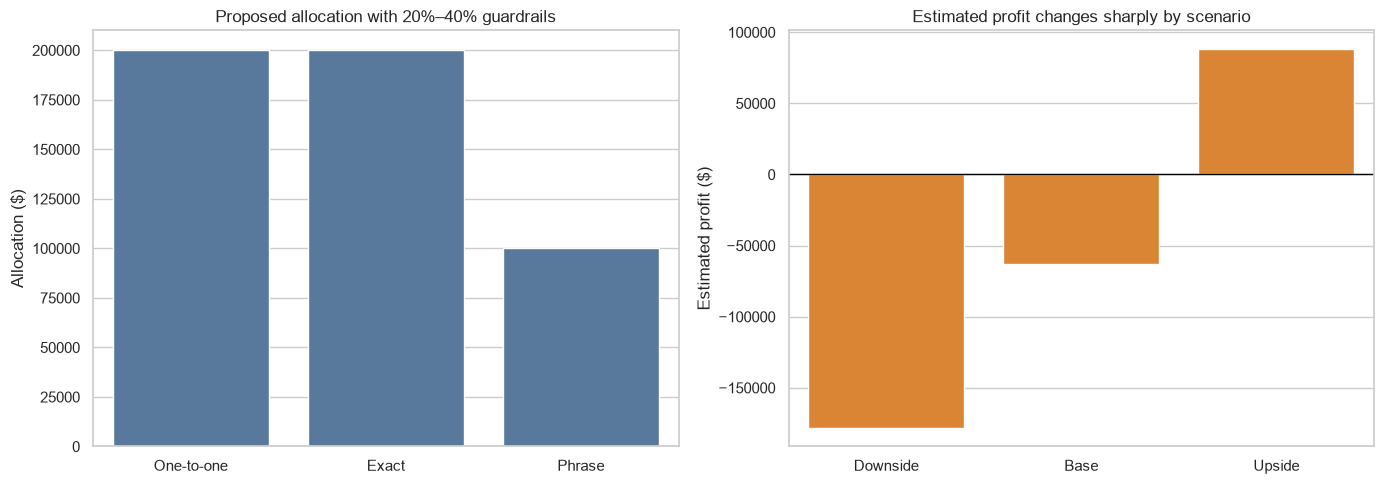

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.barplot(data=allocation, x="match_type", y="allocation", color="#4C78A8", ax=axes[0])
axes[0].set_title("Proposed allocation with 20%–40% guardrails")
axes[0].set_xlabel(""); axes[0].set_ylabel("Allocation ($)")
sns.barplot(data=sensitivity, x="scenario", y="estimated_profit", color="#F58518", ax=axes[1])
axes[1].axhline(0,color="black",lw=1); axes[1].set_title("Estimated profit changes sharply by scenario")
axes[1].set_xlabel(""); axes[1].set_ylabel("Estimated profit ($)")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "budget_and_sensitivity.png", dpi=180, bbox_inches="tight"); plt.show()

## Marketing applicability

| Area | Demonstrated here | Transferable method | Additional data required |
|---|---|---|---|
| Paid Search | Impressions→clicks→conversions→reported revenue/cost by match type and device | Funnel KPIs, unit economics, guarded allocation | Keywords/search terms, bids, quality score, attribution, incrementality, margin |
| Paid Social / Meta | Not contained | Same funnel and uncertainty framework | Campaign/ad set/creative, reach, frequency, view/click attribution, audience |
| Display | Not contained | CTR/CPC/conversion and controlled testing | Viewability, placements, reach/frequency, view-through attribution |
| Email / CRM | Not contained | Proportion tests, revenue per conversion, experiments | Sends, deliveries, opens, clicks, users, holdout assignment, unsubscribe |
| Organic | Not contained | Funnel rates and cohort uncertainty | Queries, rankings, landing pages, sessions, assisted conversions, content cost |
| Offline / brand | Not contained | Scenario planning and experimental design | Geography/store exposure, reach, brand lift, matched controls, MMM inputs |

Only the paid-search findings are evidenced here. The measurement approach can transfer to other channels, but the numerical results cannot.

## 30/60/90-day action plan

| Horizon | Action | Metrics and guardrails |
|---|---|---|
| 0–30 days | Maintain One-to-one under the 40% cap; reduce Phrase exposure; audit search terms, conversion definitions, mobile landing pages, revenue mapping, and the inconsistent published conversion-rate field. | Recalculated CTR/CVR/CPC/CPA, revenue per conversion, ROAS/ROI; no budget increase while marginal ROI is negative. |
| 31–60 days | Run controlled creative/landing-page and match-type tests with pre-registered primary outcomes; add negative keywords and separate device reporting. | Random assignment where feasible, sample-ratio checks, incremental conversions, uncertainty intervals, FDR-controlled secondary metrics. |
| 61–90 days | Reallocate only after tests reach planned sample size; scale cells with positive incremental economics and stable quality. | Incremental CPA/ROAS, gross-margin contribution, new-customer rate, attribution lag, saturation and frequency. |

For a future A/B test, define one treatment difference, randomize eligible traffic within comparable auctions, log assignment/exposure before outcomes, choose conversion rate or profit per eligible search as the primary metric, calculate sample size in advance, maintain a holdout, and analyze intention-to-treat. Do not reuse the observational comparisons here as an experimental control.

## Reproducible Results Record

In [14]:
overall = aggregate_performance(df.assign(portfolio="All paid search"), "portfolio").iloc[0]
analysis_summary = {
    "rows": int(len(df)), "months": [str(x) for x in df["month"].cat.categories],
    "ad_groups": int(df["ad_group"].nunique()),
    "overall": {k: float(overall[k]) for k in ["impressions","clicks","conversions","cost","revenue","ctr","conversion_rate","cpc","cpa","revenue_per_conversion","profit","roas","roi","profit_margin"]},
    "kruskal": {"statistic": float(kruskal.statistic), "p_value": float(kruskal.pvalue)},
    "conversion_chi_square": {"statistic": float(chi2), "p_value": float(chi_p), "cramers_v": float(cramers_v)},
    "cpa_comparisons": {
        "total": int(cpa_comparisons),
        "significant_uncorrected": int(cpa_tests["significant_uncorrected"].sum()),
        "significant_bonferroni": int(cpa_tests["significant_bonferroni"].sum()),
        "significant_fdr": int(cpa_tests["significant_fdr"].sum()),
    },
    "conversion_comparisons": {
        "total": int(conversion_comparisons),
        "significant_uncorrected": int(conversion_tests["significant_uncorrected"].sum()),
        "significant_bonferroni": int(conversion_tests["significant_bonferroni"].sum()),
        "significant_fdr": int(conversion_tests["significant_fdr"].sum()),
    },
    "budget_total": int(allocation["allocation"].sum()),
    "allocation": {str(row.match_type): int(row.allocation) for row in allocation.itertuples()},
    "decisions": {str(row.match_type): row.decision for row in decision.itertuples()},
    "base_sensitivity": sensitivity.loc[sensitivity.scenario.eq("Base")].iloc[0].to_dict(),
}
with open(OUTPUT_DIR / "analysis_summary.json", "w") as handle:
    json.dump(analysis_summary, handle, indent=2)
print(json.dumps(analysis_summary, indent=2))

{
  "rows": 190,
  "months": [
    "July",
    "August",
    "September",
    "October",
    "November"
  ],
  "ad_groups": 40,
  "overall": {
    "impressions": 2674699.0,
    "clicks": 924503.0,
    "conversions": 95996.0,
    "cost": 635372.0,
    "revenue": 561960.0,
    "ctr": 0.3456474915495164,
    "conversion_rate": 0.10383524985857266,
    "cpc": 0.6872579104664884,
    "cpa": 6.6187341139214135,
    "revenue_per_conversion": 5.853993916413184,
    "profit": -73412.0,
    "roas": 0.8844582386381521,
    "roi": -0.11554176136184786,
    "profit_margin": -0.13063563242935441
  },
  "kruskal": {
    "statistic": 11.052823828791388,
    "p_value": 0.0039802449577925085
  },
  "conversion_chi_square": {
    "statistic": 43.404514843194995,
    "p_value": 3.7568975921547217e-10,
    "cramers_v": 0.006851935888122952
  },
  "cpa_comparisons": {
    "total": 3,
    "significant_uncorrected": 2,
    "significant_bonferroni": 1,
    "significant_fdr": 2
  },
  "conversion_comparisons": 

## What This Means

The statistical tests answer a useful but limited question: which historical patterns are too consistent to dismiss as random noise under the model? They do not decide where the next dollar should go.

For this campaign, One-to-one has a lower mean CPA than Exact and Phrase after FDR correction. Its conversion advantage is also consistent but small in percentage-point terms. The negative ROI intervals remain the stronger commercial constraint. Maintain One-to-one, optimise Exact and reduce Phrase exposure while the team fixes measurement and runs prospective tests. Do not scale any group until marginal revenue covers media cost under an agreed business definition.